# Importancia de variables en la segmentación de inundaciones en el Perú

**Avance semana 7.** Autores: Gerson Andre Garrido Mansilla y Renzo Elvis Cerron Tome
(Maestría en Ciencias con mención en Inteligencia Artificial, UNI).

**Contexto.** La tesis desarrolla un sistema que genera mapas de agua a partir de imágenes
Sentinel-2. Se comparan dos modelos fundacionales geoespaciales (TerraMind v1-B y
Prithvi-EO-2.0 300M) con una U-Net. La matriz de consistencia de esta misma rama
(`entregables/matriz_consistencia/`) define las variables del estudio.

En este cuaderno se mide la importancia de las variables en dos niveles:

1. **Variables independientes de la tesis.** ¿Qué factor explica más la diferencia de IoU de agua
   entre configuraciones: la arquitectura, el esquema de entrenamiento o el método de adaptación?
2. **Variables de entrada de los modelos.** ¿Qué bandas de Sentinel-2 usan los modelos entrenados
   en el Perú para detectar el agua? Se mide con importancia por permutación.

**Protocolo.** Todo se calcula en `peru-dev`, la partición de validación peruana (174 recortes).
Las particiones de prueba no se leen. Los resultados son exploratorios y no cambian la
comparación final de la tesis.

Código: `scripts/variable_importance_dev.py` (permutación) y este cuaderno.

In [1]:
import importlib.util, json, sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(REPO / "src"))
%matplotlib inline
pd.set_option("display.precision", 4)
OUT = REPO / "outputs" / "variable_importance"
NOMBRE = {"unet": "U-Net", "terramind_v1_base": "TerraMind v1-B", "prithvi_eo_v2_300": "Prithvi-EO-2.0 300M"}
BANDA = {"COASTAL_AEROSOL": "B01 aerosol", "BLUE": "B02 azul", "GREEN": "B03 verde", "RED": "B04 rojo",
         "RED_EDGE_1": "B05 borde rojo 1", "RED_EDGE_2": "B06 borde rojo 2", "RED_EDGE_3": "B07 borde rojo 3",
         "NIR_BROAD": "B08 NIR", "NIR_NARROW": "B8A NIR estrecho", "WATER_VAPOR": "B09 vapor de agua",
         "CIRRUS": "B10 cirros", "SWIR_1": "B11 SWIR 1", "SWIR_2": "B12 SWIR 2"}
GRUPO = {"visible": "Visible (B01–B04)", "red_edge": "Borde rojo (B05–B07)", "nir": "NIR (B08, B8A)",
         "swir": "SWIR (B11, B12)", "atmospheric": "Atmosféricas (B09, B10)"}
print(json.loads((OUT / "run.json").read_text()))

{'split': 'peru-dev', 'chips': 174, 'models': ['unet'], 'seeds': ['seed0'], 'repeats': 2, 'perm_seed': 0, 'note': 'run stopped after the U-Net for time; TerraMind and Prithvi pending; values from the run log (mean of 2 permutations, 4 decimals)'}


## 1. Variables del estudio

La tabla resume las variables de la matriz de consistencia. En la sección 2 se analizan las
dimensiones X1 a X3 de la variable independiente, con la dimensión Y1 (IoU de agua) como
respuesta.

In [2]:
variables = pd.DataFrame([
    ("Independiente (X)", "X1. Arquitectura", "U-Net, TerraMind v1-B, Prithvi-EO-2.0 300M"),
    ("Independiente (X)", "X2. Esquema de entrenamiento", "Sen1Floods11; Perú"),
    ("Independiente (X)", "X3. Adaptación de dominio", "Ninguna; igualación de histogramas; FDA; AdaBN"),
    ("Independiente (X)", "X4. Tratamiento de la incertidumbre", "Sin calibrar; escalado de temperatura; ensamble"),
    ("Independiente (X)", "X5. Configuración del sistema", "Modelo seleccionado; flujo de procesamiento"),
    ("Dependiente (Y)", "Y1. Exactitud de la segmentación", "IoU de agua"),
    ("Dependiente (Y)", "Y2. Generalización al Perú", "Caída de IoU de Sen1Floods11 al Perú"),
    ("Dependiente (Y)", "Y3–Y5. Calibración, detección de errores, sistema", "ECE, AUROC, requisitos y tiempo"),
], columns=["Variable", "Dimensión", "Valores o indicador"])
variables

,Variable,Dimensión,Valores o indicador
0,Independiente (X),X1. Arquitectura,"U-Net, TerraMind v1-B, Prithvi-EO-2.0 300M"
1,Independiente (X),X2. Esquema de entrenamiento,Sen1Floods11; Perú
2,Independiente (X),X3. Adaptación de dominio,Ninguna; igualación de histogramas; FDA; AdaBN
3,Independiente (X),X4. Tratamiento de la incertidumbre,Sin calibrar; escalado de temperatura; ensamble
4,Independiente (X),X5. Configuración del sistema,Modelo seleccionado; flujo de procesamiento
5,Dependiente (Y),Y1. Exactitud de la segmentación,IoU de agua
6,Dependiente (Y),Y2. Generalización al Perú,Caída de IoU de Sen1Floods11 al Perú
7,Dependiente (Y),"Y3–Y5. Calibración, detección de errores, sistema","ECE, AUROC, requisitos y tiempo"


## 2. Importancia de las variables independientes

Se usa el IoU de agua de cada ejecución en `peru-dev` (tabla de la fase D,
`outputs/phaseD/dev_table_runs.csv`). Cada configuración tiene tres semillas.

Para medir cuánto pesa cada factor se hace una descomposición de la varianza (análisis de
varianza de dos factores con diseño balanceado). La proporción de cada factor es su suma de
cuadrados dividida entre la suma total (η²). La parte residual es la variación entre semillas.

- **2.1 Arquitectura × esquema de entrenamiento:** los tres modelos, entrenados solo con
  Sen1Floods11 o con datos del Perú (18 ejecuciones).
- **2.2 Arquitectura × método de adaptación:** U-Net y TerraMind entrenados con Sen1Floods11,
  sin adaptar o con cinco métodos de adaptación (36 ejecuciones). Prithvi no se incluye porque
  no tiene todos los métodos.

La FDA aplicada en la prueba falla por completo (IoU cercano a 0.01; `docs/phaseD_dev.md`). Como
ese solo caso domina la varianza, la descomposición 2.2 se presenta con y sin él.

In [3]:
runs = pd.read_csv(REPO / "outputs" / "phaseD" / "dev_table_runs.csv")
runs = runs[runs.seed.astype(str).str.startswith("seed")].copy()
runs["iou"] = runs.iou.astype(float)

def eta2(d, a, b):
    g = d.iou.mean()
    ss_t = ((d.iou - g) ** 2).sum()
    ss_a = d.groupby(a).iou.transform("mean").sub(g).pow(2).sum()
    ss_b = d.groupby(b).iou.transform("mean").sub(g).pow(2).sum()
    ss_ab = d.groupby([a, b]).iou.transform("mean").sub(g).pow(2).sum() - ss_a - ss_b
    ss_r = ss_t - ss_a - ss_b - ss_ab
    return pd.Series({a: ss_a, b: ss_b, "interacción": ss_ab, "residual (semillas)": ss_r}) / ss_t

ESQ = {"s1f11_src": "Sen1Floods11", "peru": "Perú"}
d1 = runs[runs.regime.isin(ESQ)].assign(arquitectura=lambda d: d.model.map(NOMBRE), esquema=lambda d: d.regime.map(ESQ))
tabla1 = d1.pivot_table(index="arquitectura", columns="esquema", values="iou", aggfunc=["mean", "std"])
display(tabla1.round(4))
e1 = eta2(d1, "arquitectura", "esquema")
display(e1.rename("η²").to_frame().round(3))

mean                  std             
esquema                Perú Sen1Floods11    Perú Sen1Floods11
arquitectura                                                 
Prithvi-EO-2.0 300M  0.9218       0.8701  0.0006       0.0011
TerraMind v1-B       0.9265       0.7027  0.0025       0.0913
U-Net                0.9415       0.8364  0.0019       0.0224

,η²
arquitectura,0.177
esquema,0.526
interacción,0.169
residual (semillas),0.128


In [4]:
MET = {"s1f11_src": "Sin adaptar", "hm": "Igualación de histogramas (prueba)", "fda": "FDA (prueba)",
       "adabn": "AdaBN", "trhm": "Igualación de histogramas (entrenamiento)", "trfda": "FDA (entrenamiento)"}
d2 = runs[runs.regime.isin(MET) & runs.model.isin(["unet", "terramind_v1_base"])]
d2 = d2.assign(arquitectura=lambda d: d.model.map(NOMBRE), método=lambda d: d.regime.map(MET))
assert len(d2) == 36, len(d2)
tabla2 = d2.pivot_table(index="método", columns="arquitectura", values="iou", aggfunc="mean").reindex(list(MET.values()))
display(tabla2.round(4))
e2 = eta2(d2, "arquitectura", "método")
d2b = d2[d2.regime != "fda"]
e2b = eta2(d2b, "arquitectura", "método")
display(pd.DataFrame({"con FDA en prueba": e2.values, "sin FDA en prueba": e2b.values},
                     index=["arquitectura", "método", "interacción", "residual (semillas)"]).round(3))

arquitectura,TerraMind v1-B,U-Net
método,,
Sin adaptar,0.7027,0.8364
Igualación de histogramas (prueba),0.8089,0.8734
FDA (prueba),0.0104,0.0116
AdaBN,0.6563,0.8969
Igualación de histogramas (entrenamiento),0.8440,0.9118
FDA (entrenamiento),0.8365,0.6151


,con FDA en prueba,sin FDA en prueba
arquitectura,0.006,0.069
método,0.923,0.249
interacción,0.052,0.496
residual (semillas),0.019,0.186


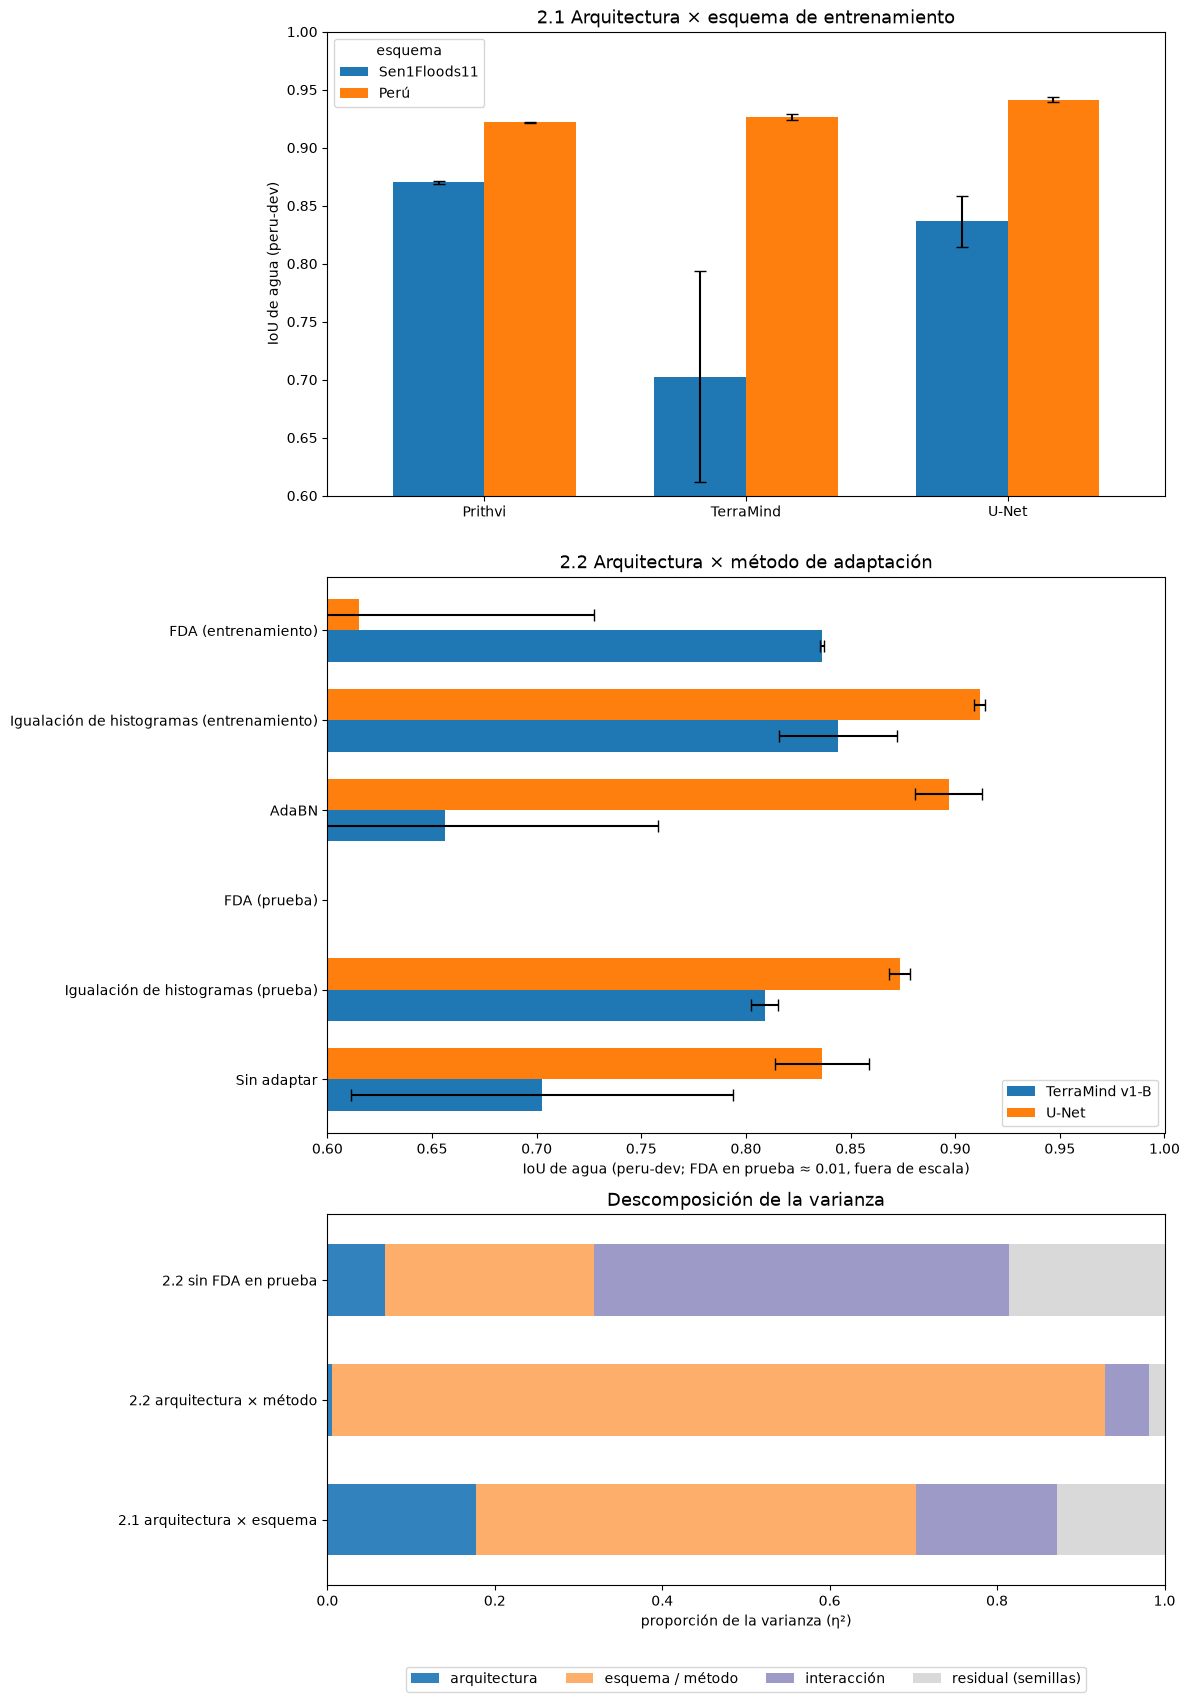

In [5]:
fig, axs = plt.subplots(3, 1, figsize=(12, 17), gridspec_kw={"height_ratios": [1, 1.2, 0.8]})
m1 = d1.groupby(["arquitectura", "esquema"]).iou.agg(["mean", "std"]).unstack()
m1["mean"][["Sen1Floods11", "Perú"]].plot.bar(ax=axs[0], yerr=m1["std"][["Sen1Floods11", "Perú"]], rot=0, capsize=4, width=0.7)
axs[0].set_ylim(0.6, 1); axs[0].set_ylabel("IoU de agua (peru-dev)"); axs[0].set_title("2.1 Arquitectura × esquema de entrenamiento", fontsize=13)
axs[0].set_xticklabels(["Prithvi", "TerraMind", "U-Net"]); axs[0].set_xlabel(""); axs[0].legend(title="esquema", loc="upper left")
m2 = d2.groupby(["método", "arquitectura"]).iou.agg(["mean", "std"]).unstack().reindex(list(MET.values()))
m2["mean"].plot.barh(ax=axs[1], xerr=m2["std"], capsize=4, width=0.7)
axs[1].set_xlim(0.6, 1); axs[1].set_xlabel("IoU de agua (peru-dev; FDA en prueba ≈ 0.01, fuera de escala)"); axs[1].set_ylabel("")
axs[1].set_title("2.2 Arquitectura × método de adaptación", fontsize=13); axs[1].legend(loc="lower right")
pd.DataFrame({"2.1 arquitectura × esquema": e1.values, "2.2 arquitectura × método": e2.values,
              "2.2 sin FDA en prueba": e2b.values},
             index=["arquitectura", "esquema / método", "interacción", "residual (semillas)"]).T.plot.barh(
    ax=axs[2], stacked=True, colormap="tab20c", width=0.6)
axs[2].set_xlim(0, 1); axs[2].set_xlabel("proporción de la varianza (η²)"); axs[2].set_title("Descomposición de la varianza", fontsize=13)
axs[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4)
plt.tight_layout(); plt.show()

## 3. Importancia de las bandas de entrada

**Método.** Se usa la importancia por permutación adaptada a imágenes. En cada recorte de
`peru-dev`, una banda se reemplaza por la misma banda de otro recorte, elegido con una
permutación aleatoria de los 174 recortes. Así la banda conserva sus valores y su textura, pero
pierde la relación con las demás bandas y con la etiqueta. La importancia es la caída del IoU de
agua respecto de la entrada sin permutar.

- Modelo: la U-Net entrenada en el Perú (configuración congelada `peru/unet`, semilla 0). Es el
  modelo que usa el sistema. La misma medición para TerraMind y Prithvi queda pendiente; el
  programa ya la soporta.
- Dos permutaciones por banda; se reporta la media.
- Las bandas vecinas están correlacionadas, y una puede reemplazar a otra. Por eso también se
  permutan **grupos** de bandas: visible, borde rojo, NIR, SWIR y atmosféricas.


In [6]:
imp = pd.read_csv(OUT / "importance.csv")
base = pd.read_csv(OUT / "runs.csv").query("kind == 'base'").set_index("model").iou
display(base.rename(index=NOMBRE).rename("IoU de agua sin permutar").to_frame().round(4))
bandas = imp[imp.kind == "banda"].pivot(index="unit", columns="model", values="iou_drop")
bandas = bandas.reindex([b for b in BANDA if b in bandas.index])[[m for m in NOMBRE if m in bandas.columns]]
bandas.index = bandas.index.map(BANDA); bandas.columns = bandas.columns.map(NOMBRE)
display(bandas.round(4).style.background_gradient(cmap="Reds", axis=None).format("{:.4f}", na_rep="—"))

,IoU de agua sin permutar
model,
U-Net,0.9397


model,U-Net
unit,
B01 aerosol,0.0502
B02 azul,0.0555
B03 verde,0.0387
B04 rojo,0.0083
B05 borde rojo 1,0.3342
B06 borde rojo 2,0.0054
B07 borde rojo 3,0.0411
B08 NIR,0.0165
B8A NIR estrecho,0.3676


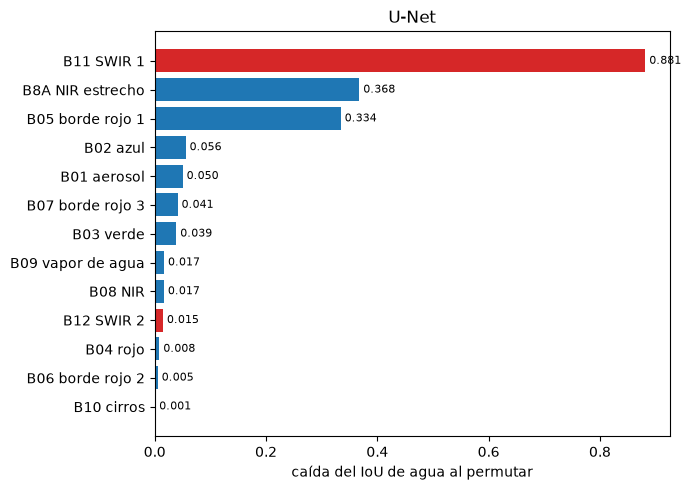

In [7]:
fig, axs = plt.subplots(1, bandas.shape[1], figsize=(7 * bandas.shape[1], 5), squeeze=False)
for ax, (m, s) in zip(axs[0], bandas.items()):
    s = s.dropna().sort_values()
    ax.barh(s.index, s.values, color=["tab:red" if "SWIR" in i else "tab:blue" for i in s.index])
    ax.set_title(m); ax.set_xlabel("caída del IoU de agua al permutar")
    for i, v in enumerate(s.values): ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

### 3.1 Grupos de bandas

Al permutar un grupo completo, las bandas del grupo ya no pueden reemplazarse entre sí. La
caída muestra cuánto depende el modelo de esa región del espectro.

model,U-Net
unit,
Visible (B01–B04),0.1029
Borde rojo (B05–B07),0.3702
"NIR (B08, B8A)",0.2264
"SWIR (B11, B12)",0.8795
"Atmosféricas (B09, B10)",0.0141


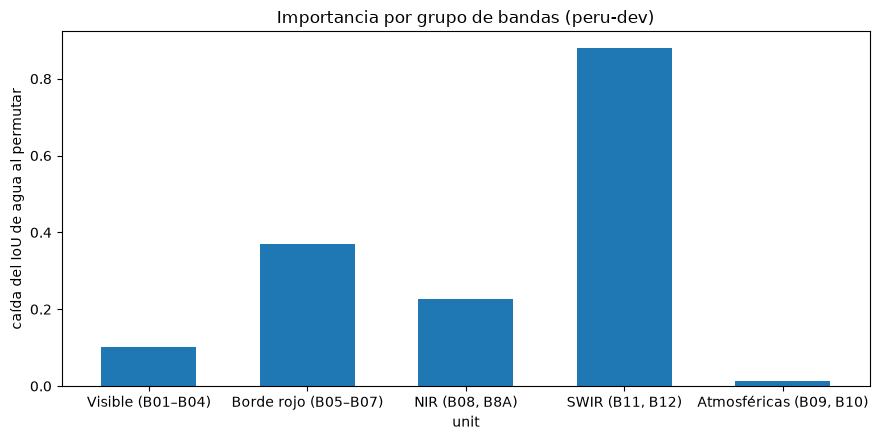

In [8]:
grupos = imp[imp.kind == "grupo"].pivot(index="unit", columns="model", values="iou_drop")
grupos = grupos.reindex([g for g in GRUPO if g in grupos.index])[[m for m in NOMBRE if m in grupos.columns]]
grupos.index = grupos.index.map(GRUPO); grupos.columns = grupos.columns.map(NOMBRE)
display(grupos.round(4).style.background_gradient(cmap="Reds", axis=None).format("{:.4f}", na_rep="—"))
ax = grupos.plot.bar(figsize=(9, 4.5), rot=0, width=0.6, legend=False)
ax.set_ylabel("caída del IoU de agua al permutar"); ax.set_title("Importancia por grupo de bandas (peru-dev)")
plt.tight_layout(); plt.show()

### 3.2 Ejemplo en un recorte

Se toma el recorte de `peru-dev` con más agua etiquetada. Se muestra la predicción de la U-Net
entrenada en el Perú (semilla 0) con la entrada original y con las bandas SWIR o las visibles
tomadas del recorte que les asigna la primera permutación. En la etiqueta, el gris es
«sin etiqueta» (nubes o desacuerdo).

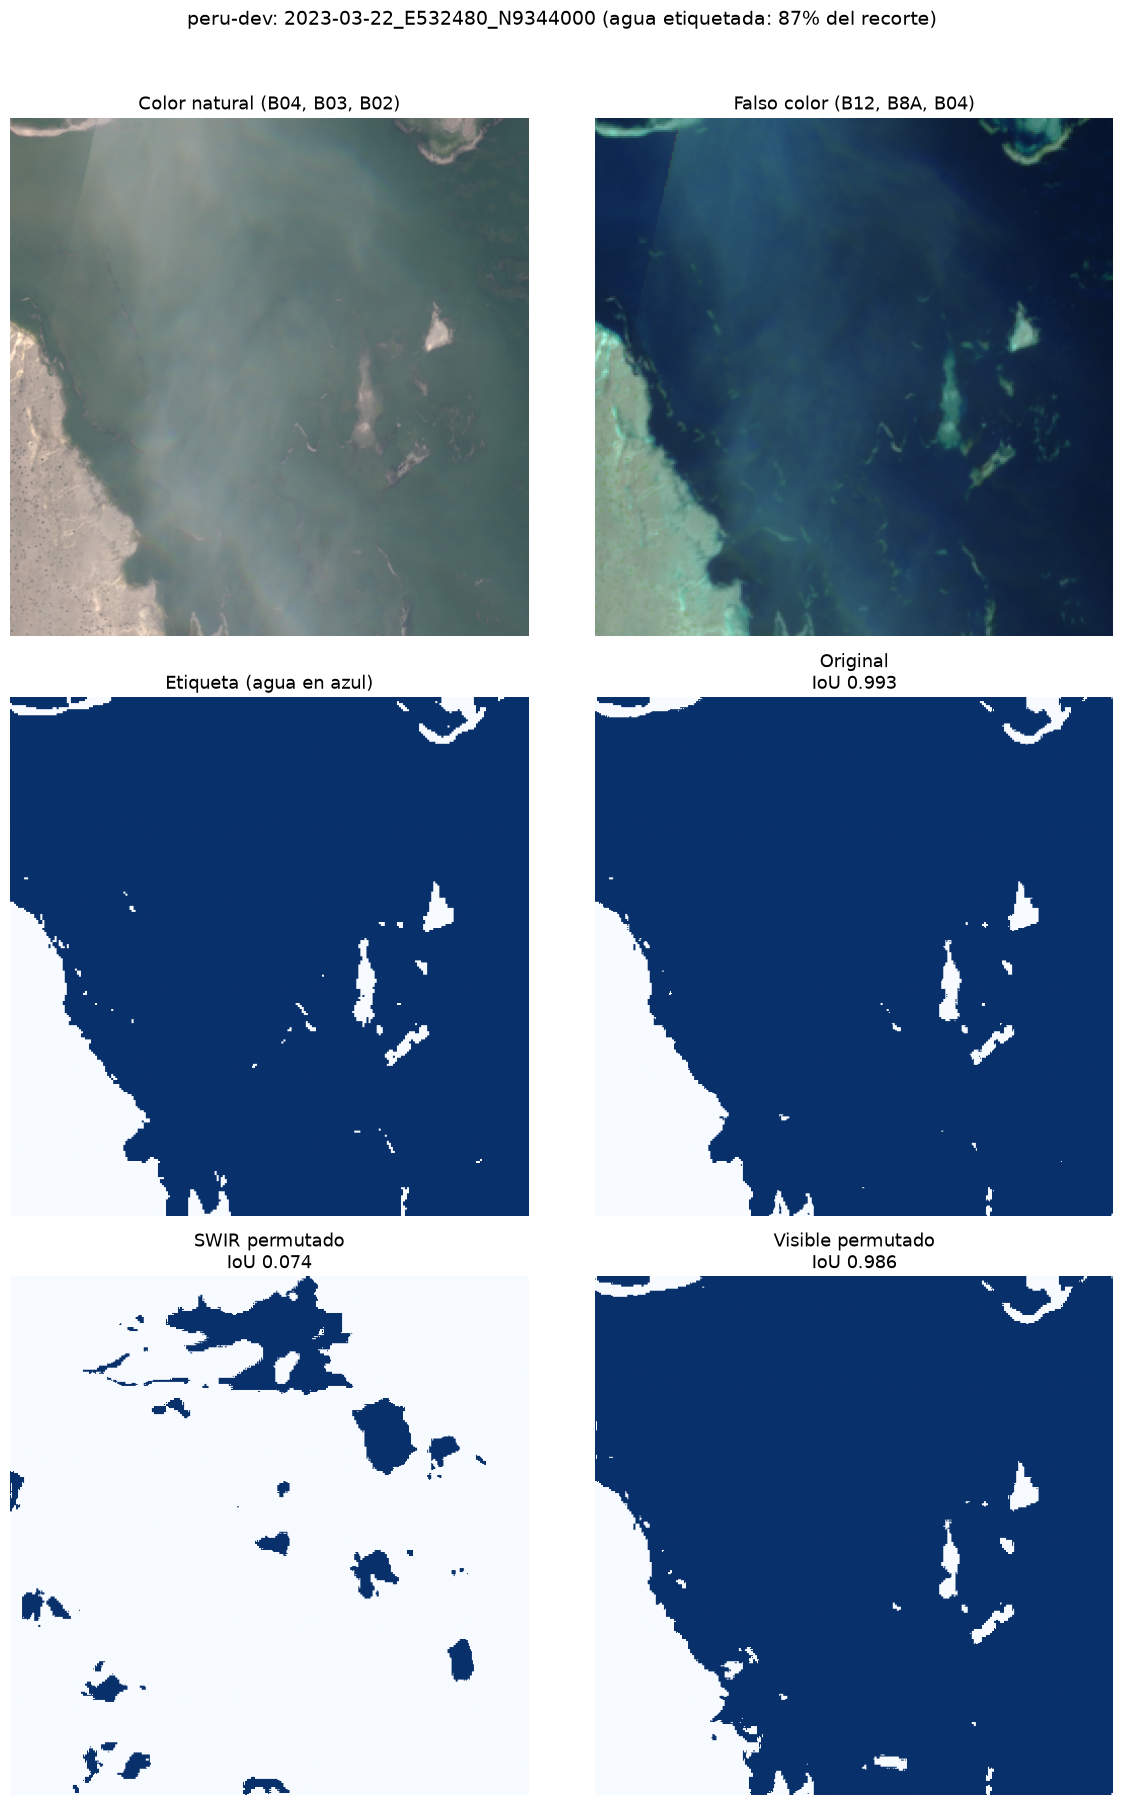

In [9]:
import os, torch, yaml
os.environ["TQDM_DISABLE"] = "1"
from terratorch.tasks import SemanticSegmentationTask
from floodseg.normalization import S2_L1C_BANDS
from floodseg.target_pool import model_input_spec, normalize

UN = REPO / "data" / "peru" / "unosat2023"
stems = (UN / "splits" / "dev.txt").read_text().split()
def leer(s):
    with rasterio.open(UN / "s2" / f"{s}.tif") as src: x = src.read().astype(np.float32)
    with rasterio.open(UN / "label" / f"{s}.tif") as src: y = src.read(1)
    return x, y
agua = [(leer(s)[1] == 1).mean() for s in stems]
i = int(np.argmax(agua)); perm = np.random.default_rng(0).permutation(len(stems))
x, y = leer(stems[i]); xo, _ = leer(stems[perm[i]])
dev = "mps" if torch.backends.mps.is_available() else "cpu"
frozen = {g["id"]: g for g in yaml.safe_load((REPO / "configs" / "frozen.yaml").read_text())["groups"]}
spec = model_input_spec(REPO / "configs" / "unet.yaml")
net = SemanticSegmentationTask.load_from_checkpoint(REPO / frozen["peru/unet"]["runs"]["seed0"]["checkpoint"], map_location="cpu").model.to(dev).eval()
def predecir(img):
    with torch.no_grad():
        o = net(normalize(img, spec)[None].to(dev)).output.float()[0]
    return (o[1] - o[0]).cpu().numpy() > 0
def permutar(grupo):
    z = x.copy(); idx = [S2_L1C_BANDS.index(b) for b in grupo]; z[idx] = xo[idx]; return z
def iou(p):
    ok, w = y != -1, y == 1
    return (p & w & ok).sum() / ((p | w) & ok).sum()
def rgb(img, bands, k=2.5):
    a = np.stack([img[S2_L1C_BANDS.index(b)] for b in bands], -1) / 10000 * k
    return np.clip(a, 0, 1)
casos = {"Original": x, "SWIR permutado": permutar(["SWIR_1", "SWIR_2"]), "Visible permutado": permutar(["COASTAL_AEROSOL", "BLUE", "GREEN", "RED"])}
fig, axs = plt.subplots(3, 2, figsize=(12, 18)); axs = axs.ravel()
axs[0].imshow(rgb(x, ["RED", "GREEN", "BLUE"])); axs[0].set_title("Color natural (B04, B03, B02)")
axs[1].imshow(rgb(x, ["SWIR_2", "NIR_NARROW", "RED"], 2.0)); axs[1].set_title("Falso color (B12, B8A, B04)")
axs[2].imshow(np.where(y == -1, 0.5, y == 1), cmap="Blues", vmin=0, vmax=1); axs[2].set_title("Etiqueta (agua en azul)")
for ax, (t, img) in zip(axs[3:], casos.items()):
    p = predecir(img); ax.imshow(p, cmap="Blues", vmin=0, vmax=1); ax.set_title(f"{t}\nIoU {iou(p):.3f}")
for ax in axs: ax.axis("off")
for ax in axs: ax.title.set_fontsize(13)
fig.suptitle(f"peru-dev: {stems[i]} (agua etiquetada: {agua[i]:.0%} del recorte)", fontsize=14, y=1.0); plt.tight_layout(rect=(0, 0, 1, 0.98)); plt.show()

## 4. Comparación con el clasificador por píxel (semana 5)

En el avance de la semana 5 se midió la importancia por permutación de un clasificador
*gradient boosting* por píxel, entrenado en `peru-train` con bandas, índices espectrales y
contexto local. Se comparan sus bandas más importantes con las de los modelos profundos.

In [10]:
fe = pd.read_csv(REPO / "outputs" / "feature_engineering" / "importance.csv")
fe = fe[fe.train == "peru-train"].sort_values("importance", ascending=False)
display(fe.head(10)[["feature", "importance", "std"]].rename(columns={
    "feature": "característica", "importance": "caída de Jaccard", "std": "desv. est."}).round(4).reset_index(drop=True))

,característica,caída de Jaccard,desv. est.
0,AWEI_nsh,0.7182,0.0015
1,MNDWI2,0.6691,0.0029
2,MNDWI,0.5796,0.0040
3,B12,0.4576,0.0017
4,MNDWI_mean7,0.3476,0.0029
5,B11,0.3417,0.0009
6,MNDWI_mean3,0.0757,0.0009
7,B05,0.0474,0.0003
8,B03,0.0229,0.0005
9,NDVI,0.0119,0.0007


## 5. Conclusiones

**Variables independientes (sección 2).**

- El esquema de entrenamiento es el factor que más pesa. Explica el 53 % de la varianza del IoU
  de agua en `peru-dev` (η² = 0.526). La arquitectura explica el 18 % y la interacción, el 17 %.
- Entrenar con datos del Perú mejora a los tres modelos: la U-Net pasa de 0.836 a 0.942,
  TerraMind de 0.703 a 0.927 y Prithvi de 0.870 a 0.922. Con datos del Perú, los tres quedan
  cerca entre sí.
- Entre los métodos de adaptación, la FDA aplicada en la prueba falla por completo y explica por
  sí sola el 92 % de la varianza. Sin ella, lo que más pesa es la interacción (η² = 0.496): el
  efecto del método depende del modelo. La FDA en entrenamiento mejora a TerraMind (0.837 frente
  a 0.703) y empeora a la U-Net (0.615 frente a 0.836). La igualación de histogramas en
  entrenamiento mejora a ambos (U-Net 0.912, TerraMind 0.844).
- Para la matriz de consistencia, esto significa que la dimensión X2 (esquema de entrenamiento)
  es la que más influye en la exactitud (Y1). Por eso la tesis estudia la adaptación sin datos
  etiquetados del Perú (OE2): busca acercarse al modelo entrenado en el Perú sin usar sus
  etiquetas.

**Bandas de entrada de la U-Net (sección 3).**

- La U-Net depende sobre todo de la banda SWIR 1 (B11). Al permutarla, el IoU de agua baja de
  0.940 a casi cero (caída de 0.88).
- Le siguen el NIR estrecho (B8A, caída de 0.37) y el borde rojo 1 (B05, 0.33). El rojo (B04),
  los cirros (B10) y el borde rojo 2 (B06) casi no influyen (caídas menores que 0.01).
- La SWIR 2 (B12) sola apenas influye (0.015), aunque está muy correlacionada con la SWIR 1. El
  modelo aprendió a usar la B11 y no la reemplaza con la B12.
- Por grupos, el orden es SWIR (0.88), borde rojo (0.37), NIR (0.23), visible (0.10) y
  atmosféricas (0.01). Las importancias no se suman: permutar un grupo completo puede bajar el
  IoU menos que permutar una sola de sus bandas.
- El resultado tiene sentido físico. El agua absorbe casi toda la radiación en el SWIR, mientras
  que la arena del desierto costero es muy brillante en esa región. Por eso el SWIR separa bien el
  agua del suelo seco en la costa peruana.

**Comparación con la semana 5 (sección 4).** El clasificador por píxel también depende del SWIR:
sus características más importantes son AWEI_nsh, MNDWI2 y MNDWI (índices que usan el SWIR) y
las bandas B12 y B11. Los dos enfoques coinciden en que el SWIR es la información clave.

**Limitaciones.**

- La permutación de bandas usa una sola semilla y dos permutaciones, solo en `peru-dev`.
- La importancia por permutación mide cuánto depende el modelo de una banda, no si la banda causa
  la presencia de agua.
- Las bandas correlacionadas se reparten la importancia; por eso se reportan también los grupos.
- La descomposición de la varianza usa tres semillas por configuración y no incluye intervalos
  de confianza.

**Pendiente.** Medir la importancia de bandas en TerraMind y Prithvi con el mismo programa
(`scripts/variable_importance_dev.py`) y en las tres semillas.
